<a href="https://colab.research.google.com/github/VidhyaSriKS/AttentionCattleNet/blob/main/AttentionCattleNet_Colab_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AttentionCattleNet on Google Colab (clean version 2)

Run the cells **in order, top to bottom**. Read the text above each cell first.

**What this version fixes compared with the first one**
- Zenodo FMD folders `0` (non-diseased) and `1` (FMD) are mapped correctly, so Zenodo is a **two-class external test** (before, all of it was wrongly labelled FMD).
- `prepare_data.py` removes held-out (external) images that are near-copies of training-collection images, and reports cross-source overlaps.
- Only **two distinct ablation variants** (no attention / SE), each with **5 seeds**. The 1x1-conv head and the linear head are the same function, so they are not run twice.
- `train.py` saves validation, test and external **logits** for ECE, the rejection threshold and Grad-CAM.
- New analysis cells: ablation summary with paired differences, confusion-matrix figure, ECE and coverage-accuracy threshold, Grad-CAM, and the ONNX export with hardware details.
- The pinkeye study is an **optional appendix** at the end (the paper mentions it in two sentences only).

**Before you start:** Runtime -> Change runtime type -> **T4 GPU** -> Save. Put `mendeley_lsd.zip` (and optionally `kaggle_devang.zip`, `sapipise.zip`) in Google Drive: `My Drive/cattle_data/`.

## Step 1. Set up Colab

In [ ]:
import torch
print("PyTorch", torch.__version__, "| GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("NO GPU: go to Runtime -> Change runtime type -> T4 GPU, then run this cell again")

PyTorch 2.11.0+cu130 | GPU available: True
Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')   # click Allow when asked

Mounted at /content/drive


In [ ]:
!pip install -q imagehash onnx onnxruntime scikit-learn pandas pillow scipy
import os
os.makedirs('/content/cattle', exist_ok=True)
%cd /content/cattle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 109.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 84.9 MB/s eta 0:00:00
/content/cattle


## Step 2. Create the code files
The next five cells write the project files into `/content/cattle`. **Do not change anything.**
(`common.py` shared helpers, `model.py` AttentionCattleNet, `prepare_data.py` cleaning and splitting, `train.py` training, `export_eval.py` ONNX export and measurement.)

In [ ]:
%%writefile common.py
"""Shared helpers (no torch dependency, so export_eval.py can run without it)."""
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support


def load_manifest(path, classes=None):
    """Read manifest.csv; optionally keep only `classes` (list of label names)."""
    df = pd.read_csv(path)
    if classes:
        df = df[df.label.isin(classes)]
    else:
        classes = sorted(df.loc[df.split != "ext_test", "label"].unique())
    return df.reset_index(drop=True), list(classes)


def get_splits(df, fold=None):
    """Return train, val, test, ext_test DataFrames.

    fold=None -> use the 'split' column (train/val/test written by prepare_data.py).
    fold=i    -> k-fold mode: test = fold i, val = fold i+1, train = the rest.
    ext_test rows (held-out sources) are never used for training or model selection.
    """
    ext = df[df.split == "ext_test"]
    core = df[df.split != "ext_test"]
    if fold is None:
        tr, va, te = (core[core.split == s] for s in ("train", "val", "test"))
    else:
        k = int(core["fold"].max()) + 1
        v = (fold + 1) % k
        te = core[core["fold"] == fold]
        va = core[core["fold"] == v]
        tr = core[~core["fold"].isin([fold, v])]
    return tr, va, te, ext


def metrics(y, p, classes):
    y, p = np.asarray(y), np.asarray(p)
    if len(y) == 0:
        return {"n": 0}
    labels = list(range(len(classes)))
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=labels, zero_division=0)
    present = sup > 0  # ignore classes absent from this set (e.g. diseased-only external sets)
    return {
        "n": int(len(y)),
        "accuracy": float(accuracy_score(y, p)),
        "macro_f1": float(f1[present].mean()),
        "balanced_acc": float(rc[present].mean()),
        "per_class": {
            c: {"precision": float(pr[i]), "recall": float(rc[i]), "f1": float(f1[i]), "support": int(sup[i])}
            for i, c in enumerate(classes)
        },
        "confusion": confusion_matrix(y, p, labels=labels).tolist(),
    }

Writing common.py


In [ ]:
%%writefile model.py
"""AttentionCattleNet and its ablation variants.

attention: 'se'   -> squeeze-and-excitation on the 960x7x7 feature map (r=16, 115,200 weights)
           'none' -> no attention block
head:      'conv' -> 1x1 conv (960->K) + global average pooling      (2,883 params for K=3; 3,844 for K=4)
           'fc'   -> global average pooling + linear (960->K)        (same maths, different graph)
"""
import torch.nn as nn
from torchvision.models import MobileNet_V3_Large_Weights, mobilenet_v3_large


class SE(nn.Module):
    def __init__(self, channels=960, r=16):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // r, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // r, channels, 1, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(self.pool(x))


class CattleNet(nn.Module):
    def __init__(self, num_classes=4, attention="se", head="conv", pretrained=True):
        super().__init__()
        weights = MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
        self.features = mobilenet_v3_large(weights=weights).features  # -> (B, 960, 7, 7)
        self.attn = SE(960) if attention == "se" else nn.Identity()
        if head == "conv":
            self.head = nn.Sequential(nn.Conv2d(960, num_classes, 1), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        elif head == "fc":
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(960, num_classes))
        else:
            raise ValueError(f"unknown head {head!r}")

    def forward(self, x):
        return self.head(self.attn(self.features(x)))

Writing model.py


In [ ]:
%%writefile prepare_data.py
"""Audit, de-duplicate, standardise and split a cattle image collection.

Layout expected:   RAW/<source>/<class>/<image files>
   e.g.  raw/sapipise/pinkeye/a.jpg     raw/kaggle_devang/lsd/b.jpg
 * <source> (first folder under RAW) is kept as provenance.
 * the class is the folder that directly contains the image.

What it does
 1. drops unreadable files, exact duplicates (SHA-256) and images whose exact/near copies
    carry two different labels;
 2. groups near-duplicates (perceptual hash, Hamming distance <= --hamming) so a group is
    never split across train/val/test;
 3. re-encodes everything the same way (RGB, 256x256, JPEG q95) into OUT/;
 4. writes OUT/manifest.csv with a group-aware stratified split.
    --holdout-source NAME  keeps that whole source out of training as 'ext_test'
    --kfold K              writes a 'fold' column (for tiny datasets such as pinkeye)
    --map a=b,c=d          rename class folders (lower-case folder name = class)
    --force SRC=class      give every image of source SRC the same class, whatever its folders

Examples
  python prepare_data.py --raw raw --out data_std --holdout-source mendeley_lsd --map sehat=healthy
  python prepare_data.py --raw raw_pinkeye --out data_pinkeye --kfold 5
"""
import argparse
import hashlib
from pathlib import Path
import collections
from itertools import combinations
import sys

import imagehash
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import StratifiedGroupKFold

EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def near_dup_groups(hashes, max_dist):
    """Union-find over 64-bit perceptual hashes; returns a group id per image."""
    hs = np.asarray(hashes, dtype=np.uint64)
    n = len(hs)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for i in range(n - 1):
        d = POP[(hs[i] ^ hs[i + 1:]).view(np.uint8).reshape(-1, 8)].sum(axis=1)
        for j in np.nonzero(d <= max_dist)[0]:
            ra, rb = find(i), find(i + 1 + int(j))
            if ra != rb:
                parent[rb] = ra
    return [find(i) for i in range(n)]


def scan(raw, label_map, force):
    rows, bad = [], 0
    for p in sorted(raw.rglob("*")):
        if p.suffix.lower() not in EXT or not p.is_file():
            continue
        try:
            with Image.open(p) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
                w, h = im.size
                ph = int(str(imagehash.phash(im, hash_size=8)), 16)
            sha = hashlib.sha256(p.read_bytes()).hexdigest()
        except Exception as e:  # corrupt / unsupported file
            print("skipping unreadable:", p, e)
            bad += 1
            continue
        rel = p.relative_to(raw)
        source = rel.parts[0] if len(rel.parts) > 1 else raw.name
        label = p.parent.name.lower()
        label = force.get(source, label_map.get(label, label))
        rows.append(dict(src_path=str(p), source=source, label=label,
                         sha256=sha, phash=ph, orig_w=w, orig_h=h))
    return pd.DataFrame(rows), bad


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--holdout-source", action="append", default=[])
    ap.add_argument("--map", default="", help="rename classes, e.g. sehat=healthy,normal=healthy")
    ap.add_argument("--force", default="", help="give every image of a source one class, e.g. zenodo_fmd=fmd")
    ap.add_argument("--hamming", type=int, default=6, help="near-duplicate threshold (of 64 bits)")
    ap.add_argument("--kfold", type=int, default=0)
    ap.add_argument("--size", type=int, default=256)
    ap.add_argument("--seed", type=int, default=0)
    a = ap.parse_args()

    raw, out = Path(a.raw), Path(a.out)
    label_map = dict(kv.split("=") for kv in a.map.split(",") if kv)
    force = dict(kv.split("=") for kv in a.force.split(",") if kv)
    df, bad = scan(raw, label_map, force)
    print(f"found {len(df)} readable images ({bad} unreadable)")

    # guard against the confusing empty-dataset crash
    if df.empty:
        sys.exit(f"No images found under {raw.resolve()}. Check the --raw path and that the datasets are unpacked.")

    # 1) exact duplicates / conflicts
    n0 = len(df)
    conflict = df.groupby("sha256").label.transform("nunique") > 1
    df = df[~conflict]
    n_conf_exact = n0 - len(df)
    df = df.drop_duplicates("sha256").reset_index(drop=True)
    n_exact = n0 - n_conf_exact - len(df)

    # 2) near-duplicate groups; drop groups with conflicting labels
    df["group"] = near_dup_groups(df.phash.tolist(), a.hamming)
    conflict = df.groupby("group").label.transform("nunique") > 1
    n_conf_near = int(conflict.sum())
    df = df[~conflict].reset_index(drop=True)
    sizes = df.groupby("group").group.transform("size")
    n_in_near = int((sizes > 1).sum())

    print(f"removed: {n_exact} exact duplicates, {n_conf_exact + n_conf_near} label-conflict images")
    print(f"kept {len(df)} images; {n_in_near} of them have near-duplicates (kept in the same split)")

    # 2b) report near-duplicate groups that span several sources (before any removal)
    pair_counts = collections.Counter()
    for grp, group_df in df.groupby('group'):
        unique_sources = sorted(group_df['source'].unique())
        if len(unique_sources) > 1:
            for src1, src2 in combinations(unique_sources, 2):
                pair_counts[(src1, src2)] += 1
    print("\nnear-duplicate groups spanning multiple sources (per pair of sources):")
    if pair_counts:
        for (src1, src2), count in sorted(pair_counts.items()):
            print(f"  {src1} <-> {src2}: {count} groups")
    else:
        print("  None")

    # 2c) leakage fix: a held-out (external) image that is a near-copy of a non-held-out image is dropped
    is_heldout = df.source.isin(a.holdout_source)
    heldout_groups = set(df[is_heldout]['group'])
    non_heldout_groups = set(df[~is_heldout]['group'])
    leaking_groups = heldout_groups.intersection(non_heldout_groups)
    leakage_mask = is_heldout & df['group'].isin(leaking_groups)
    n_removed_leakage = int(leakage_mask.sum())
    df = df[~leakage_mask].reset_index(drop=True)
    print(f"removed: {n_removed_leakage} images from held-out sources due to near-duplicate group overlap with non-held-out sources")

    # 3) splits
    df["split"], df["fold"] = "", -1
    hold = df.source.isin(a.holdout_source)
    df.loc[hold, "split"] = "ext_test"
    core = df[~hold]
    if a.kfold:
        sgkf = StratifiedGroupKFold(n_splits=a.kfold, shuffle=True, random_state=a.seed)
        for k, (_, te) in enumerate(sgkf.split(core, core.label, core.group)):
            df.loc[core.index[te], "fold"] = k
        df.loc[core.index, "split"] = "kfold"
    else:  # ~71 / 14 / 14, grouped and stratified
        te_i = next(StratifiedGroupKFold(7, shuffle=True, random_state=a.seed).split(core, core.label, core.group))[1]
        df.loc[core.index[te_i], "split"] = "test"
        rest = core.drop(core.index[te_i])
        va_i = next(StratifiedGroupKFold(6, shuffle=True, random_state=a.seed).split(rest, rest.label, rest.group))[1]
        df.loc[rest.index[va_i], "split"] = "val"
        df.loc[df.split == "", "split"] = "train"

    # 4) standardised copies + manifest
    paths = []
    for r in df.itertuples():
        dst = Path(r.source) / r.label / f"{r.sha256[:12]}.jpg"
        (out / dst.parent).mkdir(parents=True, exist_ok=True)
        with Image.open(r.src_path) as im:
            ImageOps.exif_transpose(im).convert("RGB").resize((a.size, a.size), Image.LANCZOS).save(out / dst, quality=95)
        paths.append(dst.as_posix())
    df["path"] = paths
    df[["path", "source", "label", "split", "group", "fold", "sha256", "orig_w", "orig_h"]].to_csv(out / "manifest.csv", index=False)

    print("\nimages per split x class\n", pd.crosstab(df.split, df.label))
    print("\nimages per source x class\n", pd.crosstab(df.source, df.label))
    print(f"\nwrote {out / 'manifest.csv'}")


if __name__ == "__main__":
    main()

Writing prepare_data.py


In [ ]:
%%writefile train.py
"""Train AttentionCattleNet (or an ablation variant) from manifest.csv.

  python train.py --manifest data_std/manifest.csv --root data_std --out runs/se_conv_s0 --seed 0
  # ablations:   --attention none|se   --head conv|fc
  # k-fold mode: --fold 0   (needs a manifest made with prepare_data.py --kfold 5)

Defaults follow Table II of the paper, except that the checkpoint is chosen by validation
macro-F1 (better than accuracy when classes are imbalanced).
"""
import argparse
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

from common import get_splits, load_manifest, metrics
from model import CattleNet

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


class ManifestDS(Dataset):
    def __init__(self, df, root, classes, tfm):
        self.paths = [Path(root) / p for p in df.path]
        self.y = [classes.index(l) for l in df.label]
        self.tfm = tfm

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tfm(Image.open(self.paths[i]).convert("RGB")), self.y[i]


@torch.no_grad()
def predict_logits(model, loader, device):
    """Raw logits and labels, in loader order."""
    model.eval()
    ls, ys = [], []
    for x, y in loader:
        ls.append(model(x.to(device)).float().cpu())
        ys.append(y)
    return torch.cat(ls).numpy(), torch.cat(ys).numpy()


def predict(model, loader, device):
    lg, y = predict_logits(model, loader, device)
    return y, lg.argmax(1)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--manifest", required=True)
    ap.add_argument("--root", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--classes", default="", help="comma list to keep, e.g. healthy,lsd,fmd")
    ap.add_argument("--attention", default="se", choices=["se", "none"])
    ap.add_argument("--head", default="conv", choices=["conv", "fc"])
    ap.add_argument("--fold", type=int, default=None)
    ap.add_argument("--epochs", type=int, default=15)
    ap.add_argument("--bs", type=int, default=32)
    ap.add_argument("--lr-backbone", type=float, default=1e-5)
    ap.add_argument("--lr-attn", type=float, default=1e-4)
    ap.add_argument("--lr-head", type=float, default=1e-3)
    ap.add_argument("--wd", type=float, default=1e-2)
    ap.add_argument("--smoothing", type=float, default=0.1)
    ap.add_argument("--no-class-weights", action="store_true")
    ap.add_argument("--no-pretrained", dest="pretrained", action="store_false")
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--seed", type=int, default=0)
    a = ap.parse_args()

    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed)
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    df, classes = load_manifest(a.manifest, [c for c in a.classes.split(",") if c] or None)
    tr, va, te, ext = get_splits(df, a.fold)
    print(f"classes={classes}  train={len(tr)} val={len(va)} test={len(te)} ext_test={len(ext)}  device={device}")

    train_tfm = T.Compose([
        T.Resize((256, 256)), T.RandomCrop(224), T.RandomHorizontalFlip(0.5), T.RandomRotation(20),
        T.ColorJitter(0.3, 0.3, 0.2, 0.05), T.RandomAffine(0, translate=(0.1, 0.1)),
        T.ToTensor(), T.Normalize(MEAN, STD)])
    eval_tfm = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

    def loader(d, tfm, shuffle=False):
        return DataLoader(ManifestDS(d, a.root, classes, tfm), batch_size=a.bs, shuffle=shuffle,
                          drop_last=shuffle, num_workers=a.workers, pin_memory=device == "cuda")

    tl, vl, tel = loader(tr, train_tfm, True), loader(va, eval_tfm), loader(te, eval_tfm)

    model = CattleNet(len(classes), a.attention, a.head, a.pretrained).to(device)
    groups = [(list(model.features.parameters()), a.lr_backbone),
              (list(model.attn.parameters()), a.lr_attn),
              (list(model.head.parameters()), a.lr_head)]
    opt = torch.optim.AdamW([{"params": p, "lr": lr} for p, lr in groups if p], weight_decay=a.wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=5, T_mult=2)

    counts = tr.label.value_counts()
    w = None if a.no_class_weights else torch.tensor(
        [len(tr) / (len(classes) * counts.get(c, 1)) for c in classes], dtype=torch.float32).to(device)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=a.smoothing)

    best_f1, best_state, best_ep, hist = -1.0, None, 0, []
    for ep in range(1, a.epochs + 1):
        model.train()
        tot = n = 0
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        m = metrics(*predict(model, vl, device), classes)
        hist.append(dict(epoch=ep, train_loss=tot / max(n, 1), val_acc=m["accuracy"], val_macro_f1=m["macro_f1"]))
        print(f"ep {ep:2d}  loss {tot / max(n, 1):.4f}  val acc {m['accuracy']:.4f}  val macro-F1 {m['macro_f1']:.4f}")
        if m["macro_f1"] > best_f1:
            best_f1, best_ep = m["macro_f1"], ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    torch.save({"state": best_state, "classes": classes, "attention": a.attention, "head": a.head}, out / "best.pt")
    pd.DataFrame(hist).to_csv(out / "history.csv", index=False)

    # logits of the selected checkpoint (validation / test / external) for ECE, thresholds and Grad-CAM
    vlog, vy = predict_logits(model, vl, device)
    tlog, ty = predict_logits(model, tel, device)
    np.save(out / "val_logits.npy", vlog); np.save(out / "val_labels.npy", vy)
    np.save(out / "test_logits.npy", tlog); np.save(out / "test_labels.npy", ty)
    res = {"args": vars(a), "classes": classes, "best_epoch": best_ep, "val_macro_f1": best_f1,
           "n_params": sum(p.numel() for p in model.parameters()),
           "test": metrics(ty, tlog.argmax(1), classes), "ext": {}}
    for src, g in ext.groupby("source"):
        elog, ey = predict_logits(model, loader(g, eval_tfm), device)
        np.save(out / f"ext_{src}_logits.npy", elog); np.save(out / f"ext_{src}_labels.npy", ey)
        res["ext"][src] = metrics(ey, elog.argmax(1), classes)
    (out / "metrics.json").write_text(json.dumps(res, indent=2))

    t = res["test"]
    print(f"\nTEST  acc {t['accuracy']:.4f}  macro-F1 {t['macro_f1']:.4f}  (best epoch {best_ep}, params {res['n_params']:,})")
    for c, v in t["per_class"].items():
        print(f"  {c:10s} P {v['precision']:.3f}  R {v['recall']:.3f}  F1 {v['f1']:.3f}  n={v['support']}")
    for src, m in res["ext"].items():
        print(f"EXT {src}: acc {m['accuracy']:.4f}  macro-F1 {m['macro_f1']:.4f}  n={m['n']}")


if __name__ == "__main__":
    main()

Writing train.py


In [ ]:
%%writefile export_eval.py
"""Export best.pt -> ONNX FP32, quantise (dynamic and static QDQ), then measure
accuracy, macro-F1, size and CPU latency of each with ONNX Runtime (1 thread, batch 1).

  python export_eval.py --ckpt runs/se_conv_s0/best.pt --manifest data_std/manifest.csv \
         --root data_std --out runs/se_conv_s0/onnx
Add --fold i if the run used k-fold mode. --skip-export reuses an existing fp32.onnx.
Latency columns: 'infer' = session.run only; 'e2e' = image decode + resize + normalise + run.
"""
import argparse
import json
import os
import time
from pathlib import Path

import numpy as np
import onnxruntime as ort
from onnxruntime.quantization import CalibrationDataReader, QuantFormat, QuantType, quantize_dynamic, quantize_static
from PIL import Image

from common import get_splits, load_manifest, metrics

MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)


def load_img(path):
    im = Image.open(path).convert("RGB").resize((224, 224), Image.BILINEAR)
    a = (np.asarray(im, np.float32) / 255.0 - MEAN) / STD
    return a.transpose(2, 0, 1)[None].astype(np.float32)


class Reader(CalibrationDataReader):
    def __init__(self, paths, name):
        self.it = iter([{name: load_img(p)} for p in paths])

    def get_next(self):
        return next(self.it, None)


def export_fp32(ckpt_path, onnx_path):
    import torch  # only needed here
    from model import CattleNet
    ck = torch.load(ckpt_path, map_location="cpu")
    m = CattleNet(len(ck["classes"]), ck["attention"], ck["head"], pretrained=False)
    m.load_state_dict(ck["state"]); m.eval()
    args = dict(input_names=["input"], output_names=["logits"], opset_version=18, do_constant_folding=True)
    try:
        torch.onnx.export(m, torch.zeros(1, 3, 224, 224), str(onnx_path), dynamo=False, **args)
    except TypeError:  # older torch without the dynamo flag
        torch.onnx.export(m, torch.zeros(1, 3, 224, 224), str(onnx_path), **args)
    return ck["classes"]


def evaluate(model_path, df, root, classes, warmup=20):
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    sess = ort.InferenceSession(str(model_path), so, providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    x0 = load_img(Path(root) / df.path.iloc[0])
    for _ in range(warmup):
        sess.run(None, {name: x0})
    y, p, inf, e2e = [], [], [], []
    for path, label in zip(df.path, df.label):
        t0 = time.perf_counter()
        x = load_img(Path(root) / path)
        t1 = time.perf_counter()
        out = sess.run(None, {name: x})[0]
        t2 = time.perf_counter()
        inf.append((t2 - t1) * 1e3); e2e.append((t2 - t0) * 1e3)
        y.append(classes.index(label)); p.append(int(out.argmax()))
    m = metrics(y, p, classes)
    m.update(size_mb=os.path.getsize(model_path) / 1e6,
             infer_ms=dict(mean=float(np.mean(inf)), median=float(np.median(inf)),
                           p95=float(np.percentile(inf, 95)), std=float(np.std(inf))),
             e2e_ms_median=float(np.median(e2e)))
    return m


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt", default="")
    ap.add_argument("--manifest", required=True)
    ap.add_argument("--root", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--fold", type=int, default=None)
    ap.add_argument("--calib", type=int, default=100, help="calibration images for static quantisation")
    ap.add_argument("--skip-export", action="store_true")
    a = ap.parse_args()
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)

    fp32 = out / "fp32.onnx"
    if a.skip_export:
        classes = json.loads((out / "classes.json").read_text())
    else:
        classes = export_fp32(a.ckpt, fp32)
        (out / "classes.json").write_text(json.dumps(classes))
    df, _ = load_manifest(a.manifest, classes)
    tr, va, te, ext = get_splits(df, a.fold)

    name = ort.InferenceSession(str(fp32), providers=["CPUExecutionProvider"]).get_inputs()[0].name
    calib = [Path(a.root) / p for p in tr.sample(min(a.calib, len(tr)), random_state=0).path]
    variants = {"fp32": fp32, "int8_dynamic": out / "int8_dynamic.onnx", "int8_static_qdq": out / "int8_static_qdq.onnx"}
    qsrc = fp32  # ORT recommends shape-inference pre-processing before quantising
    try:
        from onnxruntime.quantization.shape_inference import quant_pre_process
        quant_pre_process(str(fp32), str(out / "fp32_pre.onnx"), skip_symbolic_shape=True)
        qsrc = out / "fp32_pre.onnx"
    except Exception as e:
        print("quant pre-processing skipped:", e)
    quantize_dynamic(str(qsrc), str(variants["int8_dynamic"]), weight_type=QuantType.QUInt8)
    quantize_static(str(qsrc), str(variants["int8_static_qdq"]), Reader(calib, name), quant_format=QuantFormat.QDQ,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, per_channel=True)

    res = {}
    for v, path in variants.items():
        res[v] = {"test": evaluate(path, te, a.root, classes)}
        for src, g in ext.groupby("source"):
            res[v][f"ext:{src}"] = evaluate(path, g, a.root, classes)
    (out / "export_metrics.json").write_text(json.dumps(res, indent=2))

    print("\n| variant | size MB | test acc | test macro-F1 | infer ms (median / p95) | e2e ms (median) |")
    print("|---|---|---|---|---|---|")
    for v, r in res.items():
        t = r["test"]
        print(f"| {v} | {t['size_mb']:.2f} | {t['accuracy']:.4f} | {t['macro_f1']:.4f} | "
              f"{t['infer_ms']['median']:.2f} / {t['infer_ms']['p95']:.2f} | {t['e2e_ms_median']:.2f} |")


if __name__ == "__main__":
    main()

Writing export_eval.py


## Step 3. Get the datasets
Each source gets its own folder because the **source name is used to hold whole datasets out for testing**.

| Folder | Dataset | How you get it |
|---|---|---|
| `raw_main/kaggle_devang` | Kaggle Cattle Diseases Datasets (healthy / LSD / FMD) | Kaggle API (3a) or zip in Drive |
| `raw_main/zenodo_fmd` | Zenodo 7779246 (folder `0` = non-diseased, `1` = FMD) | automatic (3b) |
| `raw_main/mendeley_lsd` | Mendeley w36hpf86j2, LSD and normal skin | zip in Drive (3c) |

Kaggle is the training data. Zenodo and Mendeley are held out to test data the model never saw.

### 3a. Kaggle (training data)
Upload your `kaggle.json` when asked. If this fails, put the dataset zip in Drive as `cattle_data/kaggle_devang.zip`; cell 3c unpacks it.

In [ ]:
from google.colab import files
files.upload()   # choose kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!mkdir -p raw_zips raw_main
!kaggle datasets download -d devang03mgr/cattle-diseases-datasets -p raw_zips
!unzip -q -o raw_zips/cattle-diseases-datasets.zip -d raw_main/kaggle_devang

mv: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/devang03mgr/cattle-diseases-datasets
License(s): DbCL-1.0
100% 257M/257M [00:02<00:00, 105MB/s]



### 3b. Zenodo FMD images (automatic)

In [ ]:
import requests, shutil, pathlib
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

session = requests.Session()
session.mount('https://', HTTPAdapter(max_retries=Retry(total=5, backoff_factor=1, status_forcelist=[500, 502, 503, 504])))
rec = "7779246"
try:
    meta = session.get(f"https://zenodo.org/api/records/{rec}", timeout=60).json()
    files_ = meta["files"]
    if isinstance(files_, dict):
        files_ = list(files_.get("entries", {}).values())
    dest = pathlib.Path("raw_zips/zenodo_fmd"); dest.mkdir(parents=True, exist_ok=True)
    out = pathlib.Path("raw_main/zenodo_fmd"); out.mkdir(parents=True, exist_ok=True)
    for f in files_:
        name = f.get("key") or f.get("filename")
        url = f["links"]["self"]
        p = dest / name
        print("downloading", name)
        with session.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(p, "wb") as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)
        if name.lower().endswith(".zip"):
            shutil.unpack_archive(str(p), str(out))
        else:
            shutil.copy(p, out / name)
    print("done")
except Exception as e:
    print("Zenodo failed:", e, "\nDownload by hand from https://zenodo.org/records/7779246, put a zip named zenodo_fmd.zip in Drive/cattle_data and rerun 3c.")

downloading FMD_Cattle.zip
done


### 3c. Mendeley LSD (manual zip) and the Kaggle fallback
1. **Mendeley LSD:** open https://data.mendeley.com/datasets/w36hpf86j2, click *Download all*, save the zip as `mendeley_lsd.zip`, and upload it to `My Drive/cattle_data/`.
2. This cell unpacks any zip it still needs. Folders that already exist are skipped, so it is safe to run twice.

In [ ]:
import shutil
from pathlib import Path
%cd /content/cattle
D = Path('/content/drive/MyDrive/cattle_data')

def unpack(key, dest):
    dest = Path(dest)
    if dest.exists() and any(dest.rglob('*')):
        print('already present:', dest); return
    hits = sorted(f for f in D.glob('*.zip') if key in f.name.lower()) if D.exists() else []
    if hits:
        shutil.unpack_archive(str(hits[0]), dest); print('unpacked', hits[0].name, '->', dest)
    else:
        print('MISSING: no zip containing', repr(key), 'in', D)

unpack('kaggle',   'raw_main/kaggle_devang')   # only does something if 3a failed
unpack('zenodo',   'raw_main/zenodo_fmd')      # only does something if 3b failed
unpack('mendeley', 'raw_main/mendeley_lsd')

/content/cattle
already present: raw_main/kaggle_devang
already present: raw_main/zenodo_fmd
unpacked mendeley_lsd.zip -> raw_main/mendeley_lsd


### 3d. Check the Zenodo folders yourself (read the output)
Folder `0` should show non-diseased animals and folder `1` FMD lesions. This is why `MAP` in Step 5 has `0=healthy,1=fmd`.

folder 0: 173 images; examples: ['Calf, underside of tongue 1.jpg', 'Calf, underside of tongue 3.jpg', 'Cow mouth with teeth 1.jpg', 'Cows head, open mouth 1.jpeg']


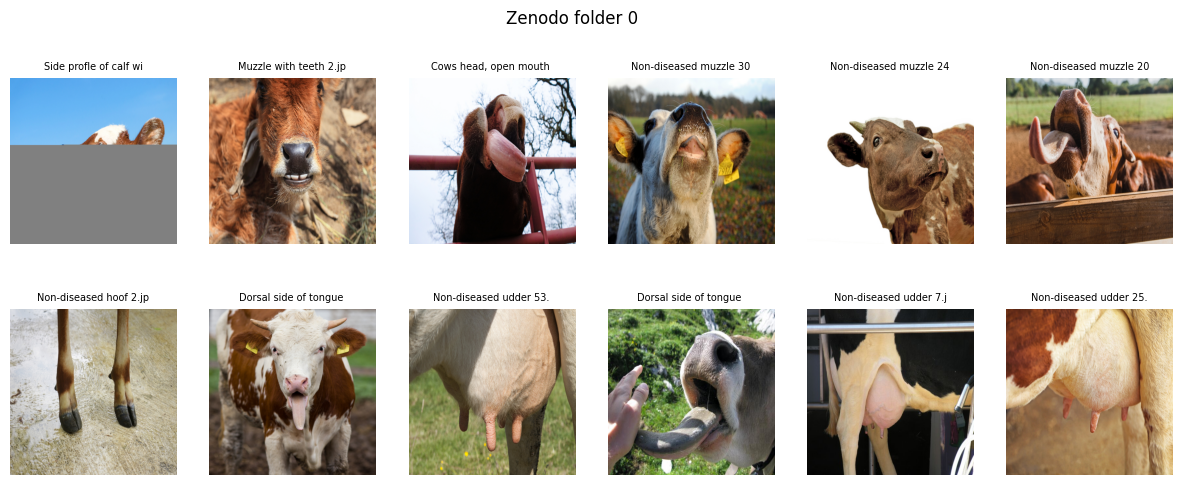

folder 1: 169 images; examples: ['1 day vesicle, cow, teat.jpg', '1 day vesicle, steer, tongue.jpg', '10 day lesions, steer, tongue.jpg', '11 day lesion, steer, heel bulb.jpg']


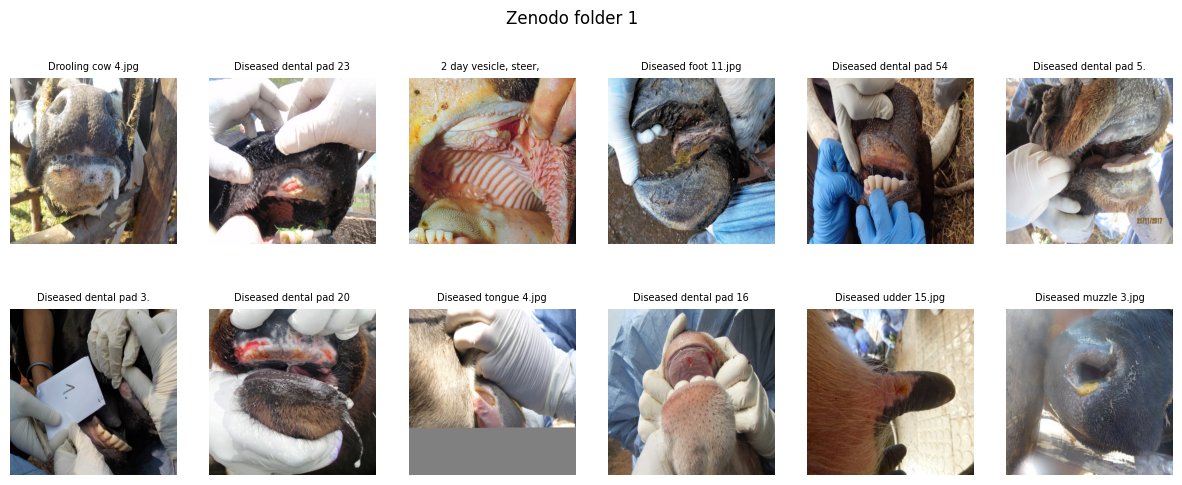

In [ ]:
import os, random
import matplotlib.pyplot as plt
from PIL import Image
base = '/content/cattle/raw_main/zenodo_fmd/FMD_Cattle'
for sub in ['0', '1']:
    d = os.path.join(base, sub)
    fs = sorted(f for f in os.listdir(d) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')))
    print(f"folder {sub}: {len(fs)} images; examples:", fs[:4])
    random.seed(42)
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.5)); fig.suptitle(f"Zenodo folder {sub}")
    for a_ in ax.ravel(): a_.axis('off')
    for a_, n in zip(ax.ravel(), random.sample(fs, min(12, len(fs)))):
        try: a_.imshow(Image.open(os.path.join(d, n))); a_.set_title(n[:22], fontsize=7)
        except Exception: a_.set_title('unreadable', fontsize=7)
    plt.show()

## Step 4. Look at what you downloaded
Lists every folder that contains images and how many. The folder that directly holds the images is used as the class name, so `MAP` in Step 5 must cover every name you see here. The cell stops with an error if nothing was found.

In [ ]:
import os
def tree(root):
    print("==", root, "(symlink!)" if os.path.islink(root) else "")
    total = 0
    for r, dirs, fs in os.walk(root):
        n = sum(f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')) for f in fs)
        total += n
        if n: print(f"{n:6d}  {r}")
    return total
n_main = tree('raw_main')
assert n_main > 0, "raw_main has no images: rerun Step 3 (the session may have been reset)"

== raw_main 
   173  raw_main/zenodo_fmd/FMD_Cattle/0
   169  raw_main/zenodo_fmd/FMD_Cattle/1
  1291  raw_main/kaggle_devang/Cows datasets/healthy
   746  raw_main/kaggle_devang/Cows datasets/foot-and-mouth
  1207  raw_main/kaggle_devang/Cows datasets/lumpy
   324  raw_main/mendeley_lsd/Lumpy Skin
   700  raw_main/mendeley_lsd/Normal Skin


## Step 5. Clean and split the data
**EDIT only if your folder names differ from Step 4.**
- `MAP` renames class folders to `healthy`, `lsd`, `fmd` (lower-case folder name = new name). `0=healthy,1=fmd` are the two Zenodo folders.
- `FORCE` must stay **empty** now (it would override `MAP` for a whole source).

The script removes unreadable files and exact duplicates, removes images whose copies carry different labels, groups near-duplicates so they stay in one split, **drops external images that are near-copies of training-collection images**, saves every image as a 256x256 JPEG, makes ~71/14/14 splits, and holds out `mendeley_lsd` and `zenodo_fmd` as external tests.

In [ ]:
%cd /content/cattle
MAP   = "normal skin=healthy,lumpy skin=lsd,lumpy=lsd,foot-and-mouth=fmd,0=healthy,1=fmd"
FORCE = ""    # keep empty
!rm -rf data_std
!python prepare_data.py --raw raw_main --out data_std --holdout-source mendeley_lsd --holdout-source zenodo_fmd --map "$MAP" --force "$FORCE"

/content/cattle
skipping unreadable: raw_main/zenodo_fmd/FMD_Cattle/0/Non-diseased udder 4.jpeg broken data stream when reading image file
found 4609 readable images (1 unreadable)
removed: 7 exact duplicates, 48 label-conflict images
kept 4554 images; 1017 of them have near-duplicates (kept in the same split)

near-duplicate groups spanning multiple sources (per pair of sources):
  kaggle_devang <-> mendeley_lsd: 277 groups
  kaggle_devang <-> zenodo_fmd: 115 groups
removed: 453 images from held-out sources due to near-duplicate group overlap with non-held-out sources

images per split x class
 label     fmd  healthy  lsd
split                      
ext_test  103      707   68
test      104      185  168
train     528      922  852
val       107      183  174

images per source x class
 label          fmd  healthy   lsd
source                           
kaggle_devang  739     1290  1194
mendeley_lsd     0      597    68
zenodo_fmd     103      110     0

wrote data_std/manifest.csv


In [ ]:
import pandas as pd
m = pd.read_csv('data_std/manifest.csv')
print(pd.crosstab(m.split, m.label), "\n")
print(pd.crosstab(m.source, m.label), "\n")
train_classes = set(m[m.split != 'ext_test'].label.unique())
assert train_classes == {'healthy', 'lsd', 'fmd'}, f"unexpected training classes: {train_classes}"
print("OK: training classes are exactly", sorted(train_classes))
print("external classes per source:", m[m.split == 'ext_test'].groupby('source').label.unique().to_dict())

label     fmd  healthy  lsd
split                      
ext_test  103      707   68
test      104      185  168
train     528      922  852
val       107      183  174 

label          fmd  healthy   lsd
source                           
kaggle_devang  739     1290  1194
mendeley_lsd     0      597    68
zenodo_fmd     103      110     0 

OK: training classes are exactly ['fmd', 'healthy', 'lsd']
external classes per source: {'mendeley_lsd': array(['lsd', 'healthy'], dtype=object), 'zenodo_fmd': array(['healthy', 'fmd'], dtype=object)}


**Save the Step 5 printout** (counts, removed images, leakage line). It fills the dataset table in the paper. If a class is nearly empty or you see odd class names, fix `MAP`, rerun Step 5, and tell me the numbers before training.

## Step 6. Look at the images yourself
12 random images per class (training collection) and per external source/class. Look for wrong labels, other animals, drawings, watermarks. Write down what you find; it goes in the paper's limitations.

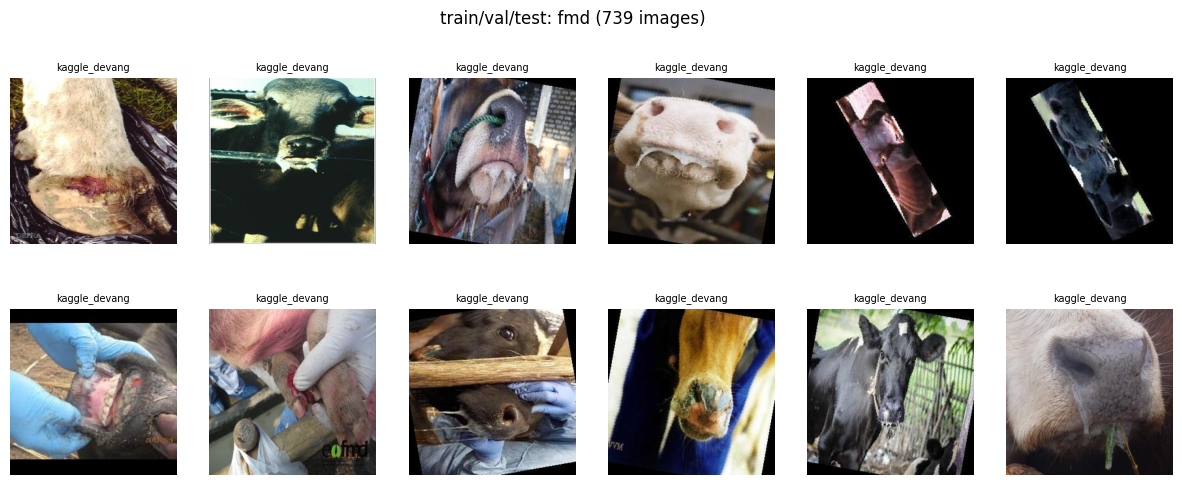

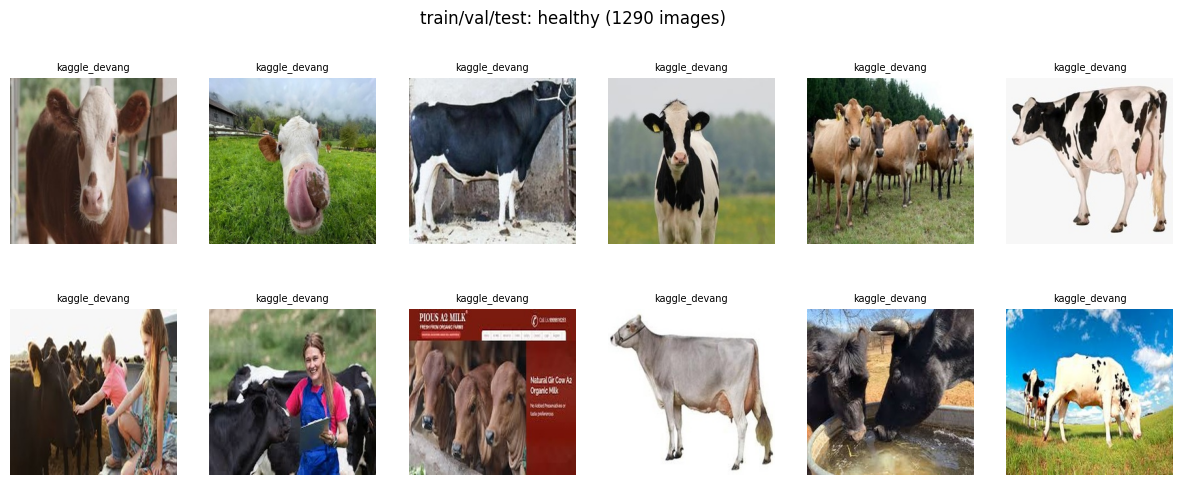

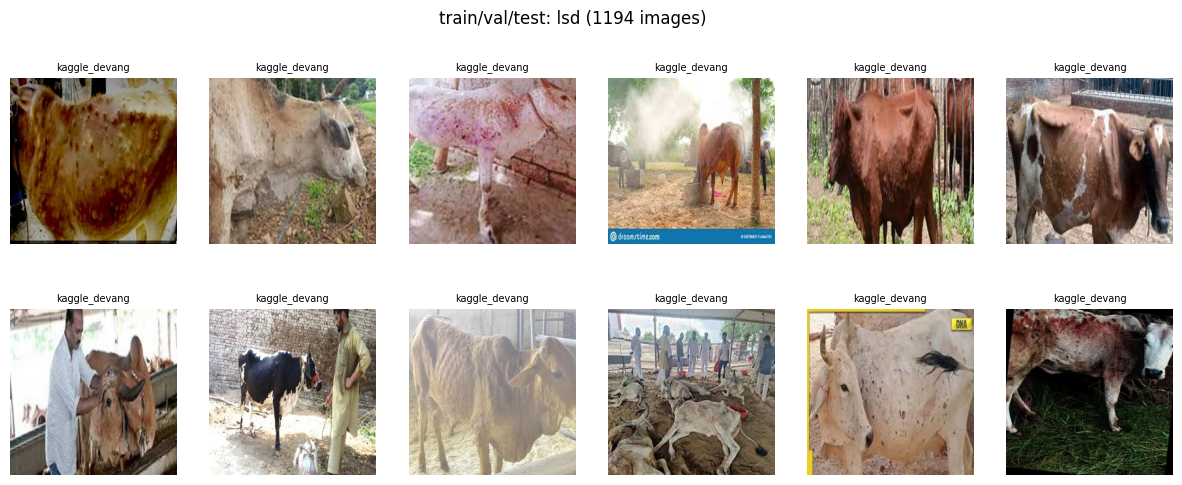

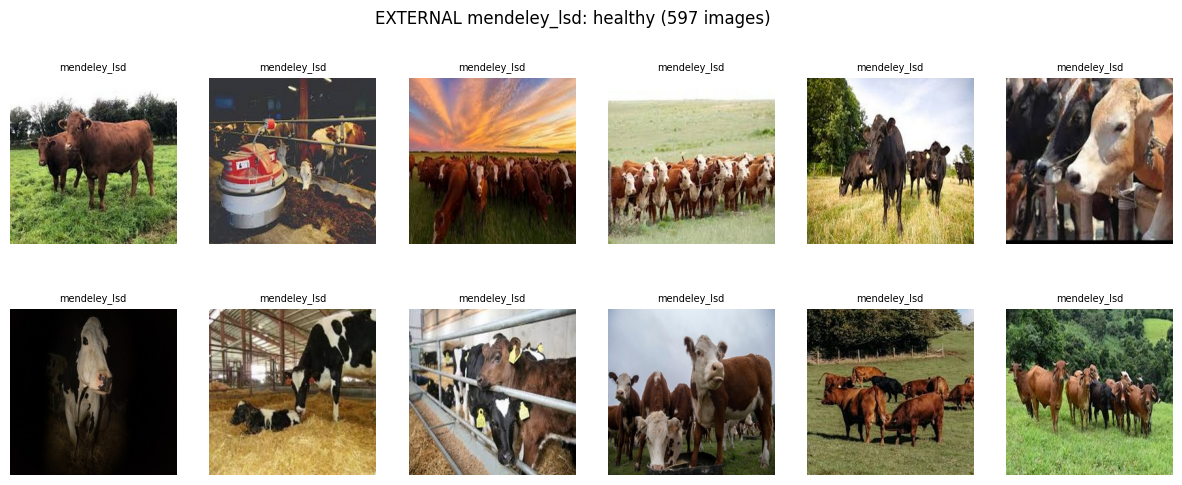

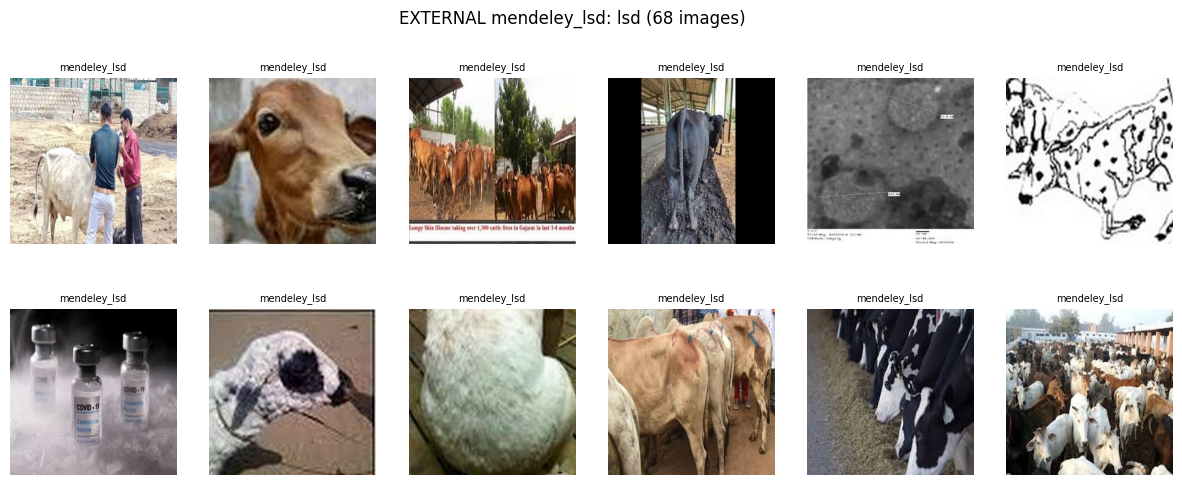

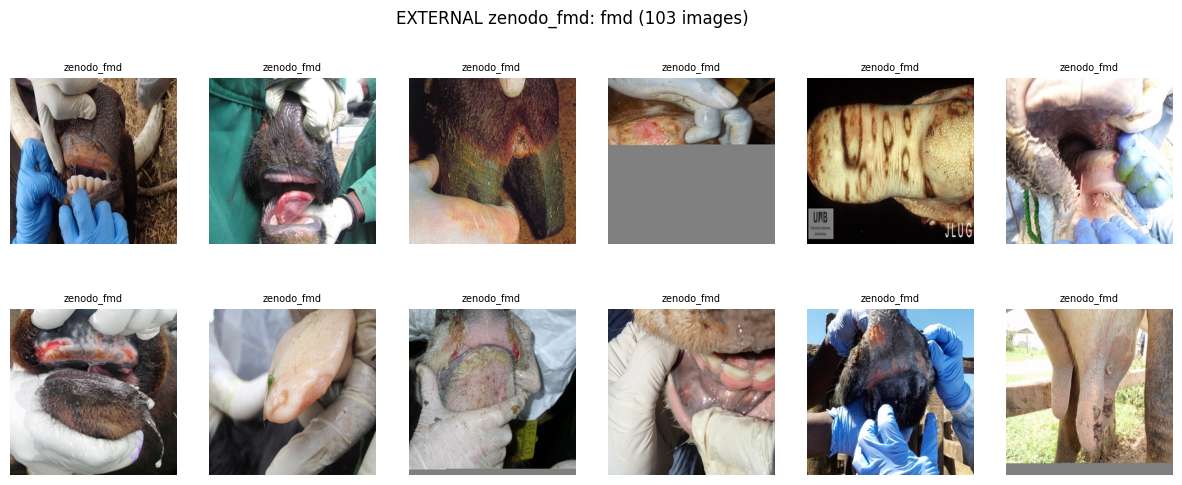

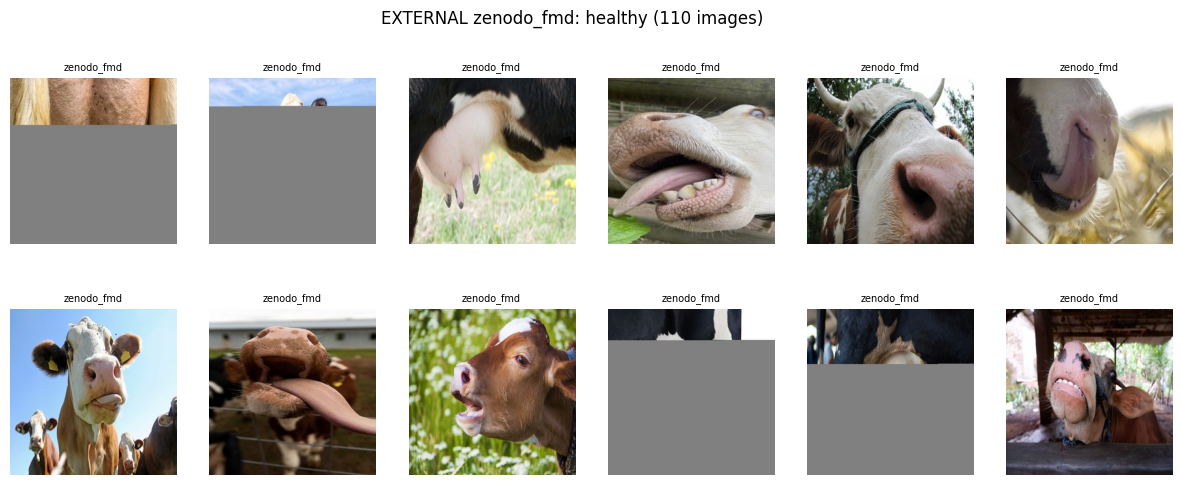

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
m = pd.read_csv('data_std/manifest.csv')
def grid(df, title, n=12):
    s = df.sample(min(n, len(df)), random_state=0)
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.5)); fig.suptitle(f"{title} ({len(df)} images)")
    for a_ in ax.ravel(): a_.axis('off')
    for a_, (_, r) in zip(ax.ravel(), s.iterrows()):
        a_.imshow(Image.open('data_std/' + r.path)); a_.set_title(r.source, fontsize=7)
    plt.show()
for lab in sorted(m.label.unique()):
    grid(m[(m.label == lab) & (m.split != 'ext_test')], f"train/val/test: {lab}")
for (src, lab), g in m[m.split == 'ext_test'].groupby(['source', 'label']):
    grid(g, f"EXTERNAL {src}: {lab}")

## Step 7. Test that training works (1 epoch, about a minute)
If it prints a per-class table at the end, everything is connected. If it errors, send me the **last 20 lines**.

In [ ]:
CLASSES = "healthy,lsd,fmd"
!python train.py --manifest data_std/manifest.csv --root data_std --classes {CLASSES} --out runs_smoke --epochs 1
!ls runs_smoke

classes=['healthy', 'lsd', 'fmd']  train=2302 val=464 test=457 ext_test=878  device=cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth
100% 21.1M/21.1M [00:00<00:00, 168MB/s]
ep  1  loss 0.8275  val acc 0.8578  val macro-F1 0.8555

TEST  acc 0.8359  macro-F1 0.8274  (best epoch 1, params 3,090,035)
  healthy    P 0.824  R 0.838  F1 0.831  n=185
  lsd        P 0.862  R 0.893  F1 0.877  n=168
  fmd        P 0.811  R 0.740  F1 0.774  n=104
EXT mendeley_lsd: acc 0.8917  macro-F1 0.7302  n=665
EXT zenodo_fmd: acc 0.7277  macro-F1 0.8069  n=213
best.pt			     ext_zenodo_fmd_logits.npy	test_logits.npy
ext_mendeley_lsd_labels.npy  history.csv		val_labels.npy
ext_mendeley_lsd_logits.npy  metrics.json		val_logits.npy
ext_zenodo_fmd_labels.npy    test_labels.npy


## Step 8. Full experiments (ablation)
Two distinct models, **5 seeds each (10 runs, roughly 40 to 60 minutes on a T4)**:
- `none`: MobileNetV3-Large, no attention, 1x1-conv head
- `se`: **AttentionCattleNet** (SE block + 1x1-conv head)

The 1x1-conv head and the linear head are the same function (and gave identical results before), so they are not run twice.
If `data_std/manifest.csv` has changed since the last run, old results in `runs/` are cleared automatically. If Colab disconnects, rerun Steps 1, 2 and the data steps, then this cell: finished runs are skipped.

In [ ]:
import subprocess, os, shutil, hashlib
%cd /content/cattle

CLASSES  = "healthy,lsd,fmd"
VARIANTS = [('none', 'conv'), ('se', 'conv')]
SEEDS    = [0, 1, 2, 3, 4]

md5 = hashlib.md5(open('data_std/manifest.csv', 'rb').read()).hexdigest()
marker = 'runs/.manifest_md5'
if not (os.path.exists(marker) and open(marker).read() == md5):
    shutil.rmtree('runs', ignore_errors=True); os.makedirs('runs')
    open(marker, 'w').write(md5)
    print('manifest changed or first run -> cleared old runs')

for att, head in VARIANTS:
    for seed in SEEDS:
        name = f'{att}_s{seed}'
        if os.path.exists(f'runs/{name}/metrics.json'):
            print('skip', name, '(done)'); continue
        cmd = ['python', 'train.py', '--manifest', 'data_std/manifest.csv', '--root', 'data_std',
               '--classes', CLASSES, '--out', f'runs/{name}', '--attention', att, '--head', head,
               '--seed', str(seed), '--epochs', '15']
        r = subprocess.run(cmd, capture_output=True, text=True)
        open(f'runs/{name}.log', 'w').write(r.stdout + r.stderr)
        print(name, 'OK' if r.returncode == 0 else 'FAILED')
        if r.returncode != 0: print(r.stderr[-1500:])
        else: print('\n'.join(r.stdout.strip().splitlines()[-6:]))

/content/cattle
manifest changed or first run -> cleared old runs
none_s0 OK
TEST  acc 0.9234  macro-F1 0.9230  (best epoch 10, params 2,974,835)
  healthy    P 0.901  R 0.930  F1 0.915  n=185
  lsd        P 0.974  R 0.905  F1 0.938  n=168
  fmd        P 0.891  R 0.942  F1 0.916  n=104
EXT mendeley_lsd: acc 0.8932  macro-F1 0.7453  n=665
EXT zenodo_fmd: acc 0.8545  macro-F1 0.8664  n=213
none_s1 OK
TEST  acc 0.9322  macro-F1 0.9319  (best epoch 13, params 2,974,835)
  healthy    P 0.905  R 0.930  F1 0.917  n=185
  lsd        P 0.975  R 0.935  F1 0.954  n=168
  fmd        P 0.915  R 0.933  F1 0.924  n=104
EXT mendeley_lsd: acc 0.8947  macro-F1 0.7414  n=665
EXT zenodo_fmd: acc 0.8451  macro-F1 0.8674  n=213
none_s2 OK
TEST  acc 0.9409  macro-F1 0.9411  (best epoch 15, params 2,974,835)
  healthy    P 0.939  R 0.919  F1 0.929  n=185
  lsd        P 0.958  R 0.952  F1 0.955  n=168
  fmd        P 0.917  R 0.962  F1 0.939  n=104
EXT mendeley_lsd: acc 0.8932  macro-F1 0.7500  n=665
EXT zenodo

## Step 9. Results tables (fills the paper's ablation, per-class and external tables)

In [ ]:
import json, os, numpy as np, pandas as pd
from scipy import stats
SEEDS = [0, 1, 2, 3, 4]
rows = []
for att in ['none', 'se']:
    for seed in SEEDS:
        f = f'runs/{att}_s{seed}/metrics.json'
        if not os.path.exists(f): continue
        r = json.load(open(f))
        row = dict(attention=att, seed=seed, params=r['n_params'],
                   test_macro_f1=r['test']['macro_f1'], test_acc=r['test']['accuracy'])
        for src, v in r['ext'].items():
            row[f'ext_{src}_acc'] = v['accuracy']; row[f'ext_{src}_macro_f1'] = v['macro_f1']
        rows.append(row)
df = pd.DataFrame(rows); df.to_csv('ablation_runs.csv', index=False)
cols = [c for c in df.columns if c not in ('attention', 'seed', 'params')]
summ = df.groupby('attention')[cols].agg(['mean', 'std'])
summ.to_csv('ablation_summary.csv')
print('parameters:', df.groupby('attention').params.first().to_dict())
print('runs per variant:', df.groupby('attention').size().to_dict())
print('\nMEAN and SAMPLE STD over seeds, in percent:')
display((summ * 100).round(2))

print('\nPAIRED DIFFERENCE (se minus none, same seed), in percentage points:')
for c in cols:
    piv = df.pivot(index='seed', columns='attention', values=c).dropna()
    if len(piv) < 2: continue
    d = (piv['se'] - piv['none']) * 100
    t, p = stats.ttest_rel(piv['se'], piv['none'])
    print(f"{c:30s} mean {d.mean():+.2f} (sd {d.std(ddof=1):.2f}, n={len(d)}), paired-t p={p:.3f}")
    print('    per seed:', '  '.join(f's{s}:{v:+.2f}' for s, v in d.items()))
print("\nNote: one fixed data split, so p-values are indicative only. If |mean diff| is about one sd, do not claim a gain.")

parameters: {'none': 2974835, 'se': 3090035}
runs per variant: {'none': 5, 'se': 5}

MEAN and SAMPLE STD over seeds, in percent:


test_macro_f1       test_acc       ext_mendeley_lsd_acc        \
                   mean   std     mean   std                 mean   std   
attention                                                                 
none              93.40  0.70    93.39  0.66                89.14  0.76   
se                93.86  0.41    93.92  0.39                89.11  1.20   

          ext_mendeley_lsd_macro_f1       ext_zenodo_fmd_acc        \
                               mean   std               mean   std   
attention                                                            
none                          74.25  0.75              83.38  2.63   
se                            74.27  1.00              82.72  0.77   

          ext_zenodo_fmd_macro_f1        
                             mean   std  
attention                                
none                        85.64  1.62  
se                          85.26  0.82


PAIRED DIFFERENCE (se minus none, same seed), in percentage points:
test_macro_f1                  mean +0.46 (sd 1.03, n=5), paired-t p=0.372
    per seed: s0:+2.24  s1:+0.29  s2:-0.41  s3:+0.12  s4:+0.07
test_acc                       mean +0.53 (sd 0.95, n=5), paired-t p=0.284
    per seed: s0:+2.19  s1:+0.22  s2:-0.22  s3:+0.22  s4:+0.22
ext_mendeley_lsd_acc           mean -0.03 (sd 1.58, n=5), paired-t p=0.968
    per seed: s0:-0.75  s1:+1.50  s2:-1.05  s3:+1.80  s4:-1.65
ext_mendeley_lsd_macro_f1      mean +0.03 (sd 1.54, n=5), paired-t p=0.970
    per seed: s0:-0.60  s1:+1.67  s2:-1.44  s3:+1.68  s4:-1.17
ext_zenodo_fmd_acc             mean -0.66 (sd 2.63, n=5), paired-t p=0.606
    per seed: s0:-3.29  s1:-0.47  s2:+0.00  s3:+3.29  s4:-2.82
ext_zenodo_fmd_macro_f1        mean -0.38 (sd 1.43, n=5), paired-t p=0.584
    per seed: s0:-1.33  s1:-1.09  s2:-0.04  s3:+1.99  s4:-1.44

Note: one fixed data split, so p-values are indicative only. If |mean diff| is about one sd, do not cl

         precision  recall     f1  support
healthy      0.935   0.935  0.935    185.0
lsd          0.970   0.946  0.958    168.0
fmd          0.926   0.962  0.943    104.0
         healthy  lsd  fmd
healthy      173    5    7
lsd            8  159    1
fmd            4    0  100


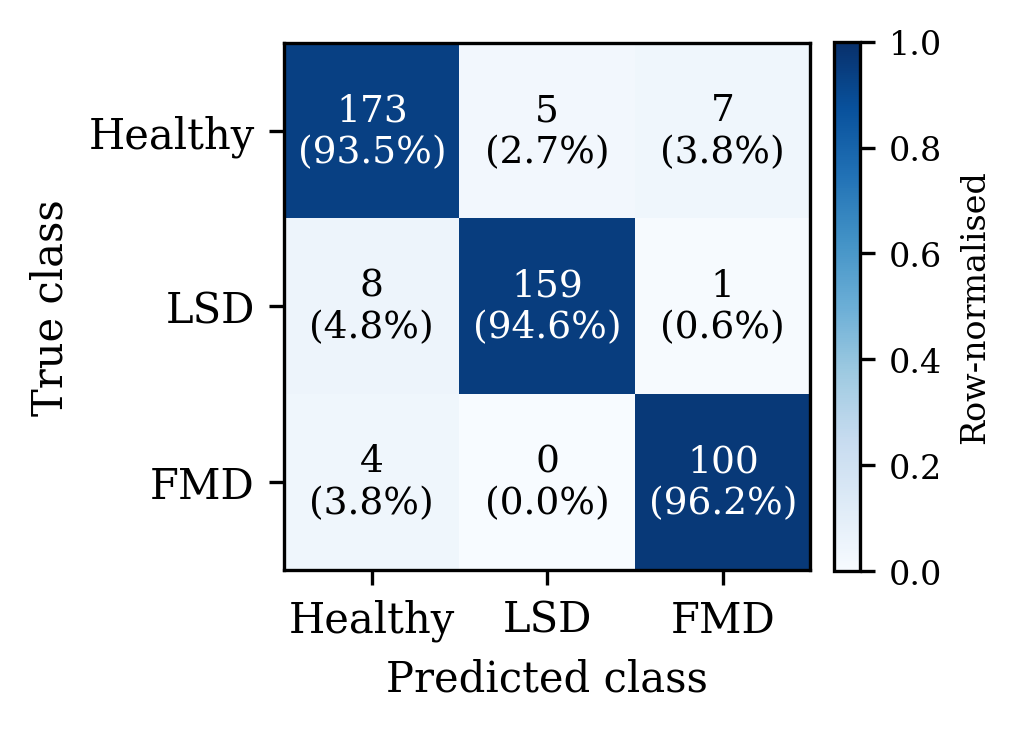


EXTERNAL SOURCES (seed 0):
mendeley_lsd: n=665  acc 0.8857  macro-F1 0.7393
         healthy  lsd  fmd
healthy      550   37   10
lsd           27   39    2
fmd            0    0    0
zenodo_fmd: n=213  acc 0.8216  macro-F1 0.8532
         healthy  lsd  fmd
healthy       83   10   17
lsd            0    0    0
fmd            5    6   92


In [ ]:
# Per-class table, confusion matrix (saved as fig_confusion.png) and external results for the main model, seed 0
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
run = 'runs/se_s0'
r = json.load(open(f'{run}/metrics.json')); classes = r['classes']
print(pd.DataFrame(r['test']['per_class']).T.round(3))
cm = np.array(r['test']['confusion'])
print(pd.DataFrame(cm, index=classes, columns=classes))
names = [c.upper() if len(c) <= 3 else c.capitalize() for c in classes]
norm = cm / cm.sum(1, keepdims=True)
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(3.4, 3.0), dpi=300)
im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, fontsize=10); ax.set_yticklabels(names, fontsize=10)
ax.set_xlabel('Predicted class', fontsize=10); ax.set_ylabel('True class', fontsize=10)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{cm[i, j]}\n({norm[i, j] * 100:.1f}%)', ha='center', va='center', fontsize=9,
                color='white' if norm[i, j] > 0.55 else 'black')
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.ax.tick_params(labelsize=8); cb.set_label('Row-normalised', fontsize=8)
fig.tight_layout(); fig.savefig('fig_confusion.png'); plt.show()

print('\nEXTERNAL SOURCES (seed 0):')
for src, v in r['ext'].items():
    print(f"{src}: n={v['n']}  acc {v['accuracy']:.4f}  macro-F1 {v['macro_f1']:.4f}")
    print(pd.DataFrame(v['confusion'], index=classes, columns=classes))

### 9b. Calibration (ECE) and the rejection threshold
Uses the logits saved by `train.py` for seed 0. The threshold is chosen on **validation** only (smallest confidence threshold whose accepted predictions reach 95% accuracy), then applied unchanged to test and the external sets. Because of label smoothing 0.1 the maximum confidence is about 0.933 for 3 classes, so thresholds above that are meaningless.

ECE (15 bins), mean confidence, accuracy:
  val                    ECE 0.0952   conf 0.837   acc 0.918   n=464
  test                   ECE 0.1083   conf 0.837   acc 0.945   n=457
  ext_mendeley_lsd       ECE 0.0694   conf 0.819   acc 0.886   n=665
  ext_zenodo_fmd         ECE 0.0964   conf 0.757   acc 0.822   n=213

Chosen threshold tau = 0.53 (validation)
  val                    coverage 0.940   accuracy on accepted 0.952
  test                   coverage 0.954   accuracy on accepted 0.963
  ext_mendeley_lsd       coverage 0.926   accuracy on accepted 0.919
  ext_zenodo_fmd         coverage 0.793   accuracy on accepted 0.911


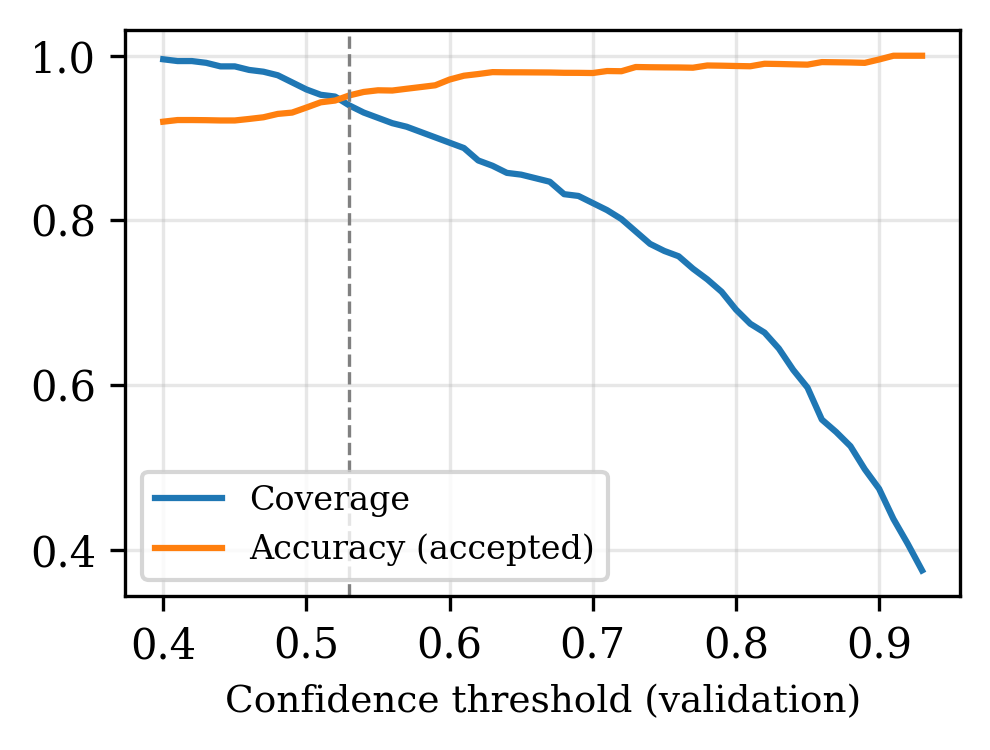

In [ ]:
import glob, os, json, numpy as np, matplotlib.pyplot as plt
from scipy.special import softmax
run = 'runs/se_s0'
sets = {'val': 'val', 'test': 'test'}
for f in sorted(glob.glob(f'{run}/ext_*_logits.npy')):
    k = os.path.basename(f)[:-len('_logits.npy')]; sets[k] = k
D = {k: (softmax(np.load(f'{run}/{v}_logits.npy'), axis=1), np.load(f'{run}/{v}_labels.npy')) for k, v in sets.items()}

def ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e

def cov_acc(p, y, t):
    keep = p.max(1) >= t
    return (keep.mean(), (p.argmax(1)[keep] == y[keep]).mean()) if keep.any() else (0.0, float('nan'))

print('ECE (15 bins), mean confidence, accuracy:')
for k, (p, y) in D.items():
    print(f"  {k:22s} ECE {ece(p, y):.4f}   conf {p.max(1).mean():.3f}   acc {(p.argmax(1) == y).mean():.3f}   n={len(y)}")

ths = np.round(np.arange(0.40, 0.931, 0.01), 2)
pv, yv = D['val']
curve = [cov_acc(pv, yv, t) for t in ths]
ok = [t for t, (c, a) in zip(ths, curve) if c > 0 and a >= 0.95]
tau = ok[0] if ok else None
if tau is None:
    print('\nNo threshold in 0.40-0.93 reaches 95% accuracy on validation: report this as a finding, do not invent a threshold.')
else:
    print(f'\nChosen threshold tau = {tau:.2f} (validation)')
    for k, (p, y) in D.items():
        c, a = cov_acc(p, y, tau); print(f"  {k:22s} coverage {c:.3f}   accuracy on accepted {a:.3f}")

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(3.4, 2.6), dpi=300)
ax.plot(ths, [c for c, a in curve], label='Coverage'); ax.plot(ths, [a for c, a in curve], label='Accuracy (accepted)')
if tau is not None: ax.axvline(tau, ls='--', c='gray', lw=0.8)
ax.set_xlabel('Confidence threshold (validation)', fontsize=9); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('fig_coverage.png'); plt.show()

### 9c. Grad-CAM (where does the model look?)
Shows 4 correct and 4 wrong test predictions for seed 0. **Look at the picture and write down honestly** whether the heat is on the lesion or on the background / barn / watermark. If it is often on the background, that is a result to report, not hide.

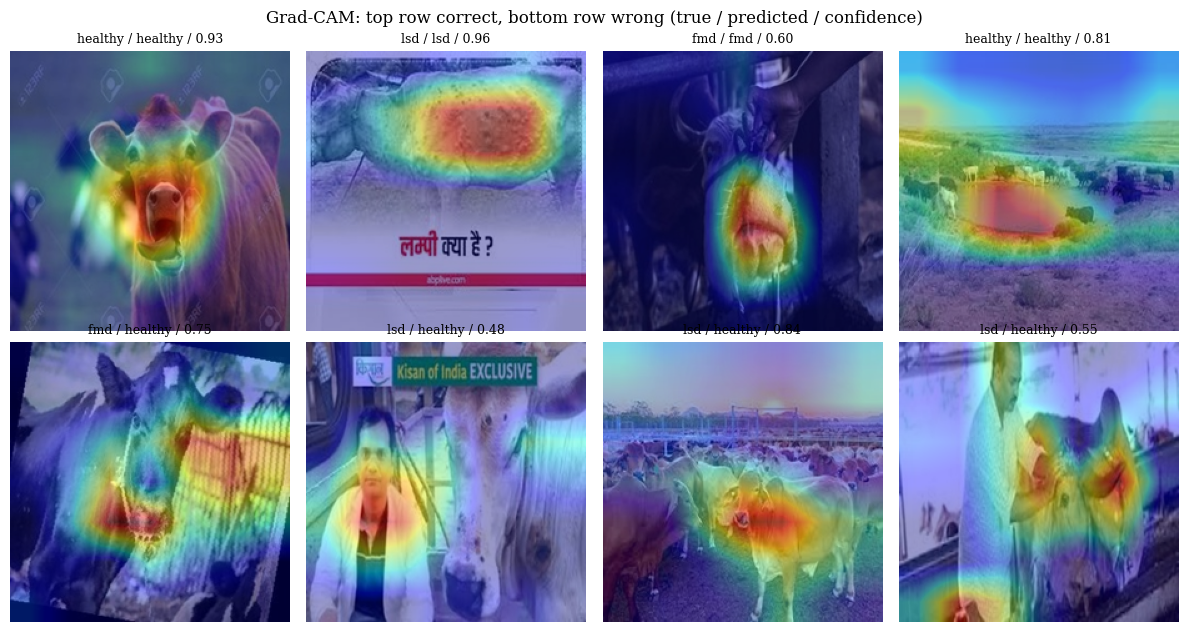

In [ ]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms as T
from common import load_manifest, get_splits
from model import CattleNet

run = 'runs/se_s0'
ck = torch.load(f'{run}/best.pt', map_location='cpu'); classes = ck['classes']
model = CattleNet(len(classes), ck['attention'], ck['head'], pretrained=False)
model.load_state_dict(ck['state']); model.eval()
df, _ = load_manifest('data_std/manifest.csv', classes); tr, va, te, ext = get_splits(df)
tl = np.load(f'{run}/test_logits.npy'); ty = np.load(f'{run}/test_labels.npy')
pred = tl.argmax(1); prob = torch.softmax(torch.tensor(tl), 1).numpy()
rng = np.random.RandomState(0)
good = rng.choice(np.where(pred == ty)[0], 4, replace=False)
badpool = np.where(pred != ty)[0]; bad = rng.choice(badpool, min(4, len(badpool)), replace=False)
tfm = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def gradcam(img):
    x = tfm(img).unsqueeze(0); model.zero_grad()
    f = model.features(x); f.retain_grad()
    out = model.head(model.attn(f)); c = int(out.argmax(1)); out[0, c].backward()
    cam = F.relu((f.grad.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)[0, 0].detach().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

fig, ax = plt.subplots(2, 4, figsize=(12, 6.4))
for a_ in ax.ravel(): a_.axis('off')
for row, idxs in enumerate([good, bad]):
    for col, i in enumerate(idxs):
        img = Image.open('data_std/' + te.path.iloc[i]).convert('RGB').resize((224, 224))
        ax[row, col].imshow(img); ax[row, col].imshow(gradcam(img), cmap='jet', alpha=0.4)
        ax[row, col].set_title(f"{classes[ty[i]]} / {classes[pred[i]]} / {prob[i].max():.2f}", fontsize=9)
fig.suptitle('Grad-CAM: top row correct, bottom row wrong (true / predicted / confidence)')
fig.tight_layout(); fig.savefig('fig_gradcam.png', dpi=300); plt.show()

## Step 10. Export to ONNX, quantize, measure
Exports the main model (`se_s0`), makes the dynamic and static INT8 versions, and measures size, accuracy and speed on the test set and the external sets. Speed is measured on **Colab's CPU with 1 thread, which is not your target device**: say so in the paper, or repeat on the real phone / Raspberry Pi. If INT8 is not faster than FP32, report that honestly.

In [ ]:
!python export_eval.py --ckpt runs/se_s0/best.pt --manifest data_std/manifest.csv --root data_std --out runs/se_s0/onnx

/content/cattle/export_eval.py:47: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, torch.zeros(1, 3, 224, 224), str(onnx_path), dynamo=False, **args)

| variant | size MB | test acc | test macro-F1 | infer ms (median / p95) | e2e ms (median) |
|---|---|---|---|---|---|
| fp32 | 12.35 | 0.9453 | 0.9455 | 7.13 / 10.01 | 9.73 |
| int8_dynamic | 3.31 | 0.9322 | 0.9306 | 31.31 / 36.72 | 34.08 |
| int8_static_qdq | 3.58 | 0.8928 | 0.8923 | 10.00 / 12.65 | 12.55 |


In [ ]:
# Hardware and versions for the paper's measurement paragraph
import onnxruntime, torch, platform
!lscpu | grep -E "Model name|^CPU\(s\)|Thread"
print("onnxruntime", onnxruntime.__version__, "| torch", torch.__version__, "| python", platform.python_version())

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2
onnxruntime 1.31.0 | torch 2.11.0+cu130 | python 3.13.15


## Step 11. Save everything to Google Drive
Colab deletes its files when the session ends. Run this to keep the results, figures, code and the cleaned manifest.

In [ ]:
!mkdir -p /content/drive/MyDrive/cattle_results_v2
!cp -r runs /content/drive/MyDrive/cattle_results_v2/
!cp -f ablation_runs.csv ablation_summary.csv fig_*.png /content/drive/MyDrive/cattle_results_v2/ 2>/dev/null
!cp -f common.py model.py prepare_data.py train.py export_eval.py /content/drive/MyDrive/cattle_results_v2/
!cp data_std/manifest.csv /content/drive/MyDrive/cattle_results_v2/manifest_main.csv
!ls /content/drive/MyDrive/cattle_results_v2

ablation_runs.csv     export_eval.py	 fig_gradcam.png    prepare_data.py
ablation_summary.csv  fig_confusion.png  manifest_main.csv  runs
common.py	      fig_coverage.png	 model.py	    train.py


In [ ]:
# Optional: also download everything as one zip to your computer
import shutil
from google.colab import files
shutil.make_archive('/content/cattle_results_v2', 'zip', '/content/cattle', 'runs')
files.download('/content/cattle_results_v2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Appendix (optional): pinkeye pilot
The paper mentions this in two sentences only. Skip it unless you want to reproduce the 5-fold pilot. It needs `sapipise.zip` in Drive. The Roboflow export keeps images directly in `train/valid/test` with a `_classes.csv` per split, so the first cell rebuilds class folders from those CSV files. **Read the printed column names and counts**: you should get about 176 pinkeye and 108 healthy images.

In [ ]:
import shutil, pandas as pd
from pathlib import Path
%cd /content/cattle
D = Path('/content/drive/MyDrive/cattle_data')
if not (Path('raw_pinkeye/sapipise').exists() and any(Path('raw_pinkeye/sapipise').rglob('*'))):
    z = next(iter(sorted(D.glob('*sapipise*.zip'))), None)
    assert z is not None, 'sapipise.zip not found in Drive/cattle_data'
    shutil.unpack_archive(str(z), 'raw_pinkeye/sapipise')
src, dst = Path('raw_pinkeye/sapipise'), Path('raw_pinkeye_clean/sapipise')
shutil.rmtree('raw_pinkeye_clean', ignore_errors=True)
RENAME = {'sehat': 'healthy', 'healthy': 'healthy', 'pinkeye': 'pinkeye'}
n = 0
for split in ['train', 'valid', 'test']:
    csvp = src / split / '_classes.csv'
    if not csvp.exists(): print('no _classes.csv in', split); continue
    t = pd.read_csv(csvp); t.columns = [c.strip() for c in t.columns]
    print(split, 'columns:', list(t.columns), 'rows:', len(t))
    fcol, ccols = t.columns[0], list(t.columns[1:])
    for _, r in t.iterrows():
        hot = [c for c in ccols if r[c] == 1]
        if len(hot) != 1: continue
        lab = RENAME.get(hot[0].lower(), hot[0].lower())
        f = src / split / str(r[fcol]).strip()
        if f.exists():
            (dst / lab).mkdir(parents=True, exist_ok=True); shutil.copy(f, dst / lab / f"{split}_{f.name}"); n += 1
print('copied', n, 'images')
!for d in raw_pinkeye_clean/sapipise/*/; do echo "$d: $(ls "$d" | wc -l)"; done

/content/cattle
train columns: ['filename', 'pinkeye', 'sehat'] rows: 227
valid columns: ['filename', 'pinkeye', 'sehat'] rows: 29
test columns: ['filename', 'pinkeye', 'sehat'] rows: 28
copied 284 images
ls: cannot access 'seed'$'\n''0   -1.328262'$'\n''1   -1.086170'$'\n''2   -0.042101'$'\n''3    1.985537'$'\n''4   -1.437729'$'\n''dtype: float64': No such file or directory
seed
0   -1.328262
1   -1.086170
2   -0.042101
3    1.985537
4   -1.437729
dtype: float64: 0
ls: cannot access 'seed'$'\n''0   -1.328262'$'\n''1   -1.086170'$'\n''2   -0.042101'$'\n''3    1.985537'$'\n''4   -1.437729'$'\n''dtype: float64': No such file or directory
seed
0   -1.328262
1   -1.086170
2   -0.042101
3    1.985537
4   -1.437729
dtype: float64: 0


In [ ]:
!rm -rf data_pinkeye
!python prepare_data.py --raw raw_pinkeye_clean --out data_pinkeye --kfold 5

found 284 readable images (0 unreadable)
removed: 0 exact duplicates, 0 label-conflict images
kept 284 images; 20 of them have near-duplicates (kept in the same split)

near-duplicate groups spanning multiple sources (per pair of sources):
  None
removed: 0 images from held-out sources due to near-duplicate group overlap with non-held-out sources

images per split x class
 label  healthy  pinkeye
split                  
kfold      108      176

images per source x class
 label     healthy  pinkeye
source                    
sapipise      108      176

wrote data_pinkeye/manifest.csv


In [ ]:
import subprocess, os, json, pandas as pd
os.makedirs('runs_pink', exist_ok=True)
for k in range(5):
    cmd = ['python', 'train.py', '--manifest', 'data_pinkeye/manifest.csv', '--root', 'data_pinkeye',
           '--classes', 'healthy,pinkeye', '--fold', str(k), '--out', f'runs_pink/f{k}',
           '--attention', 'se', '--head', 'conv', '--bs', '16']
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(f'fold {k}', 'OK' if r.returncode == 0 else 'FAILED')
    if r.returncode != 0: print(r.stderr[-1500:])
rows = []
for k in range(5):
    t = json.load(open(f'runs_pink/f{k}/metrics.json'))['test']
    rows.append(dict(fold=k, n=t['n'], macro_f1=t['macro_f1'], acc=t['accuracy'], pinkeye_recall=t['per_class']['pinkeye']['recall']))
pk = pd.DataFrame(rows); display(pk.round(3)); print(pk[['macro_f1', 'acc', 'pinkeye_recall']].agg(['mean', 'std']).round(3))

fold 0 OK
fold 1 OK
fold 2 OK
fold 3 OK
fold 4 OK


,fold,n,macro_f1,acc,pinkeye_recall
0,0,56,0.868,0.875,0.912
1,1,56,0.855,0.857,0.794
2,2,55,0.888,0.891,0.853
3,3,57,0.908,0.912,0.914
4,4,60,0.840,0.850,0.846


      macro_f1    acc  pinkeye_recall
mean     0.872  0.877           0.864
std      0.027  0.025           0.050


## What goes where in the paper
| Paper item | Where the numbers come from |
|---|---|
| Dataset table, cleaning counts, split sizes | Step 5 printout, `manifest_main.csv` |
| Ablation table (mean +/- std, paired difference) | Step 9 first cell, `ablation_summary.csv` |
| Per-class table, confusion matrix figure | Step 9 second cell, `fig_confusion.png` |
| External test table | Step 9 second cell (external sources), `ablation_summary.csv` |
| ECE, rejection threshold, coverage figure | Step 9b, `fig_coverage.png` |
| Grad-CAM figure and what you observe | Step 9c, `fig_gradcam.png` |
| Size, accuracy, latency of FP32 / INT8, hardware | Step 10 |
| Pinkeye pilot (two sentences) | Appendix |

## If something goes wrong
- **`found 0 readable images` or `KeyError: 'sha256'`:** `raw_main` is empty (session reset). Rerun Steps 3 and 4. Step 4 now stops with a clear message.
- **"CUDA out of memory":** add `'--bs', '16'` to the train command in Step 8.
- **Kaggle 401/403:** use the zip-in-Drive fallback (3c).
- **Extra class names (for example `mastitis`) in Step 5:** fix `MAP`, rerun Step 5.
- **Any other error:** send me the last 20 lines and the step number.